Implement a learning rate scheduler in Neural Networks by manually adjusting learning rates during training based on performance trends, avoiding built-in schedulers and ensuring stable weight updates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].copy()

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()

X = df[features].to_numpy(dtype=float)
y = df[target].to_numpy(dtype=float).reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y.ravel()
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42,
    stratify=y_temp.ravel()
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 55
Validation samples: 12
Testing samples: 12


In [2]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
b2 = np.zeros((1, output_size))

def sigmoid(z):
    z = np.clip(z, -30, 30)
    return 1 / (1 + np.exp(-z))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.maximum(0, z1)
    z2 = a1 @ W2 + b2
    output = sigmoid(z2)
    return z1, a1, output

def calculate_loss(y_true, y_pred):
    y_pred = np.clip(y_pred, 1e-8, 1 - 1e-8)
    return -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

print("Neural network initialized.")

Neural network initialized.


In [3]:
learning_rate = 0.01
min_learning_rate = 0.0001
lr_factor = 0.5
patience = 10
max_epochs = 200

train_losses = []
val_losses = []
learning_rates = []

best_val_loss = float("inf")
best_weights = None
epochs_without_improvement = 0

for epoch in range(max_epochs):
    # Forward pass
    z1, a1, output = forward(X_train)

    # Calculate gradients
    delta2 = (output - y_train) / len(y_train)
    dW2 = a1.T @ delta2
    db2 = np.sum(delta2, axis=0, keepdims=True)

    delta1 = (delta2 @ W2.T) * (z1 > 0)
    dW1 = X_train.T @ delta1
    db1 = np.sum(delta1, axis=0, keepdims=True)

    # Clip gradients for stable updates
    gradients = [dW1, db1, dW2, db2]
    for grad in gradients:
        np.clip(grad, -1.0, 1.0, out=grad)

    # Update weights
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    # Measure losses after the update
    _, _, train_output = forward(X_train)
    _, _, val_output = forward(X_val)

    train_loss = calculate_loss(y_train, train_output)
    val_loss = calculate_loss(y_val, val_output)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    learning_rates.append(learning_rate)

    # Save the best model weights
    if val_loss < best_val_loss - 1e-5:
        best_val_loss = val_loss
        best_weights = (
            W1.copy(), b1.copy(), W2.copy(), b2.copy()
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Reduce learning rate when validation loss plateaus
    if epochs_without_improvement >= patience:
        new_lr = max(learning_rate * lr_factor, min_learning_rate)

        if new_lr < learning_rate:
            learning_rate = new_lr
            epochs_without_improvement = 0
            print(
                f"Epoch {epoch + 1}: learning rate reduced to "
                f"{learning_rate:.5f}"
            )
        elif learning_rate <= min_learning_rate:
            print("Minimum learning rate reached.")
            break

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train Loss={train_loss:.4f}, "
            f"Validation Loss={val_loss:.4f}, "
            f"LR={learning_rate:.5f}"
        )

# Restore weights with the best validation performance
if best_weights is not None:
    W1, b1, W2, b2 = best_weights

print("Best validation loss:", round(best_val_loss, 4))

Epoch 20: Train Loss=0.6603, Validation Loss=0.9500, LR=0.01000
Epoch 40: Train Loss=0.6049, Validation Loss=0.8313, LR=0.01000
Epoch 60: Train Loss=0.5670, Validation Loss=0.7435, LR=0.01000
Epoch 80: Train Loss=0.5399, Validation Loss=0.6775, LR=0.01000
Epoch 100: Train Loss=0.5194, Validation Loss=0.6268, LR=0.01000
Epoch 120: Train Loss=0.5032, Validation Loss=0.5873, LR=0.01000
Epoch 140: Train Loss=0.4898, Validation Loss=0.5558, LR=0.01000
Epoch 160: Train Loss=0.4782, Validation Loss=0.5302, LR=0.01000
Epoch 180: Train Loss=0.4680, Validation Loss=0.5091, LR=0.01000
Epoch 200: Train Loss=0.4588, Validation Loss=0.4912, LR=0.01000
Best validation loss: 0.4912


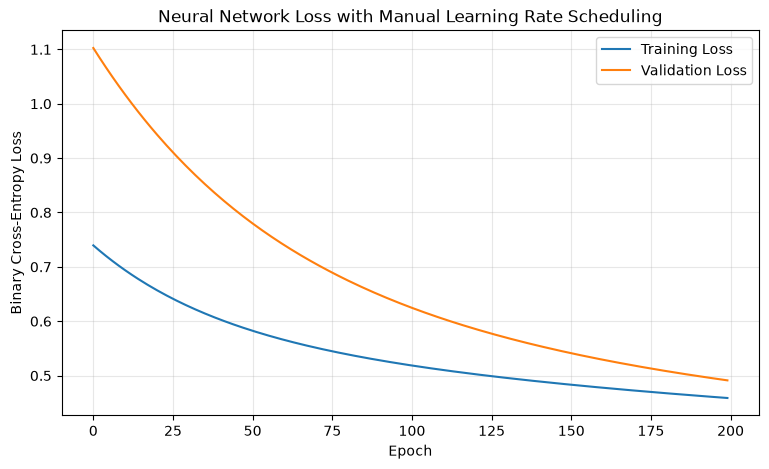

In [4]:
plt.figure(figsize=(9, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Loss with Manual Learning Rate Scheduling")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

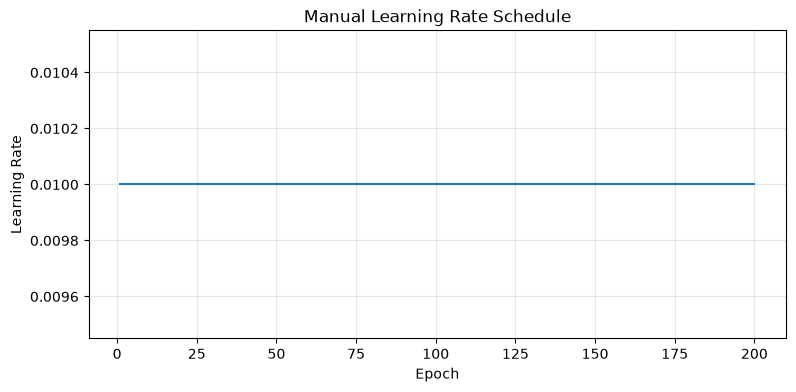

Initial learning rate: 0.01
Final learning rate: 0.01
Epochs trained: 200


In [5]:
plt.figure(figsize=(9, 4))
plt.step(
    range(1, len(learning_rates) + 1),
    learning_rates,
    where="post"
)
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Manual Learning Rate Schedule")
plt.grid(True, alpha=0.3)
plt.show()

print("Initial learning rate:", learning_rates[0])
print("Final learning rate:", learning_rates[-1])
print("Epochs trained:", len(train_losses))

In [6]:
_, _, test_output = forward(X_test)
test_predictions = (test_output >= 0.5).astype(int)

tp = np.sum((y_test == 1) & (test_predictions == 1))
tn = np.sum((y_test == 0) & (test_predictions == 0))
fp = np.sum((y_test == 0) & (test_predictions == 1))
fn = np.sum((y_test == 1) & (test_predictions == 0))

accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
precision = tp / max(tp + fp, 1)
recall = tp / max(tp + fn, 1)
f1 = 2 * precision * recall / max(precision + recall, 1e-12)

print("Test Results")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Test Results
Accuracy: 0.5833
Precision: 0.7
Recall: 0.7778
F1 Score: 0.7368


In [7]:
print("Initial training loss:", round(train_losses[0], 4))
print("Final training loss:", round(train_losses[-1], 4))
print("Best validation loss:", round(min(val_losses), 4))
print("Learning rate reductions:",
      sum(
          learning_rates[i] < learning_rates[i - 1]
          for i in range(1, len(learning_rates))
      ))

if train_losses[-1] < train_losses[0]:
    print("Training loss decreased during training.")
else:
    print("Training loss did not decrease; review the learning rate.")

if val_losses[-1] > min(val_losses) + 0.02:
    print("Validation loss rose after its best point; possible overfitting.")
else:
    print("Validation loss remained close to its best value.")

Initial training loss: 0.7395
Final training loss: 0.4588
Best validation loss: 0.4912
Learning rate reductions: 0
Training loss decreased during training.
Validation loss remained close to its best value.
